In [1]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
# Create student performance data
df = pd.DataFrame({
    "Math": [50, 60, 70, 80, 90, 95],
    "Science": [55, 65, 72, 85, 88, 98],
    "Study_Hours": [1, 2, 3, 4, 5, 6]
})

# Display the dataset
print(df)

   Math  Science  Study_Hours
0    50       55            1
1    60       65            2
2    70       72            3
3    80       85            4
4    90       88            5
5    95       98            6


In [3]:
# Display dataset information
print("Shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

# Display summary statistics
print("\nStatistics:")
print(df.describe())

Shape: (6, 3)

Missing values:
Math           0
Science        0
Study_Hours    0
dtype: int64

Statistics:
            Math    Science  Study_Hours
count   6.000000   6.000000     6.000000
mean   74.166667  77.166667     3.500000
std    17.440375  15.992707     1.870829
min    50.000000  55.000000     1.000000
25%    62.500000  66.750000     2.250000
50%    75.000000  78.500000     3.500000
75%    87.500000  87.250000     4.750000
max    95.000000  98.000000     6.000000


In [4]:
# Create the scaler
scaler = StandardScaler()

# Scale all features
X_scaled = scaler.fit_transform(df)

# Display scaled values
print(pd.DataFrame(
    X_scaled,
    columns=df.columns
).round(2))

   Math  Science  Study_Hours
0 -1.52    -1.52        -1.46
1 -0.89    -0.83        -0.88
2 -0.26    -0.35        -0.29
3  0.37     0.54         0.29
4  0.99     0.74         0.88
5  1.31     1.43         1.46


In [5]:
# Reduce 3 features to 2 components
pca = PCA(n_components=2)

# Transform the scaled data
X_pca = pca.fit_transform(X_scaled)

# Store the new components
pca_df = pd.DataFrame(
    X_pca,
    columns=["PC1", "PC2"]
)

# Display the reduced dataset
print(pca_df.round(2))

    PC1   PC2
0 -2.60 -0.02
1 -1.50  0.04
2 -0.52 -0.07
3  0.69  0.15
4  1.51 -0.17
5  2.42  0.06


In [6]:
# Display variance captured by each component
print("PC1 variance:", round(
    pca.explained_variance_ratio_[0] * 100, 2
), "%")

print("PC2 variance:", round(
    pca.explained_variance_ratio_[1] * 100, 2
), "%")

# Calculate total variance retained
total = pca.explained_variance_ratio_.sum() * 100
print("Total variance retained:", round(total, 2), "%")

PC1 variance: 99.53 %
PC2 variance: 0.35 %
Total variance retained: 99.88 %


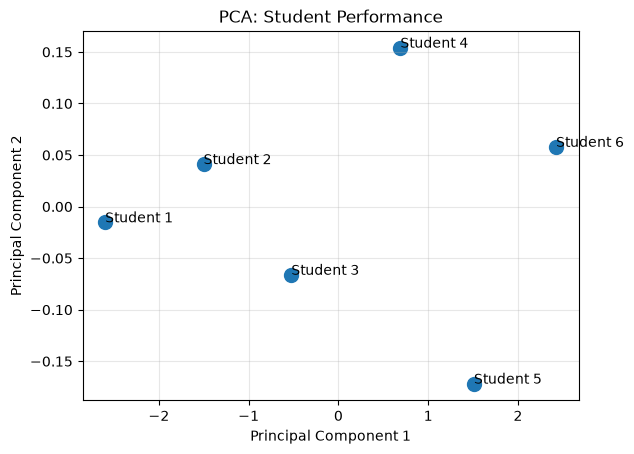

In [7]:
# Plot students using the two components
plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    s=100
)

# Label each student
for i in range(len(pca_df)):
    plt.annotate(
        f"Student {i + 1}",
        (pca_df["PC1"][i], pca_df["PC2"][i])
    )

# Add chart details
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Student Performance")
plt.grid(alpha=0.3)
plt.show()

In [8]:
# Show the original features
print("Original dataset:")
print(df)

# Show the reduced features
print("\nPCA dataset:")
print(pca_df.round(2))

Original dataset:
   Math  Science  Study_Hours
0    50       55            1
1    60       65            2
2    70       72            3
3    80       85            4
4    90       88            5
5    95       98            6

PCA dataset:
    PC1   PC2
0 -2.60 -0.02
1 -1.50  0.04
2 -0.52 -0.07
3  0.69  0.15
4  1.51 -0.17
5  2.42  0.06


In [9]:
# Keep enough components to retain 95% variance
pca_95 = PCA(n_components=0.95)

# Transform the standardized data
X_pca_95 = pca_95.fit_transform(X_scaled)

# Display the number of selected components
print("Original features:", df.shape[1])
print("Selected components:", pca_95.n_components_)
print(
    "Variance retained:",
    round(pca_95.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Original features: 3
Selected components: 1
Variance retained: 99.53 %


In [10]:
# Print the PCA summary
print("Original shape:", df.shape)
print("Reduced shape:", X_pca.shape)
print("Components:", pca.n_components_)
print(
    f"Variance retained: "
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

Original shape: (6, 3)
Reduced shape: (6, 2)
Components: 2
Variance retained: 99.88%
